# Prepare and inspect the shared questions

This phase follows exploration and precedes feature creation. **No API calls, model loads or generated features.** All six decision models will reuse the same saved task definitions and questions. Only the wording appropriate to each dataset's actual task is generated.

## 1. Validate source meanings and freeze the 18 task schemas and group every row

Definitions are hard-coded in `config/1. question_preparation/dataset_semantics.yaml`, with source URLs and unresolved facts explicitly recorded. Raw target values, feature names and CSVs remain unchanged. All 80 official text fields have descriptions; undocumented details remain identified as such.

This notebook performs the same full offline preparation as `python -m src.jev.preparation`. Completed versions are reused. Exact text is preserved; this step does not approve text truncation or a live API call.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.jev.preparation import prepare_questions, preparation_tables
from src.jev.provider import semantic_question
from src.jev.inputs import prepared_row
from src.jev.design import BINARY, MULTICLASS, REGRESSION, COMMON
from src.visualize import figures, style
from src.visualize.questions import prepared_storage_figure
style.apply()
NOTEBOOK = "1. question_preparation/01_prepare_questions"
begin_report()
report_section("1. Source-backed task schemas")
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("question_preparation")
save_resolved_config(cfg, NOTEBOOK)
bank, input_folder, prepared = prepare_questions(cfg)
tables = preparation_tables(bank)
display_local(tables["datasets"].drop(columns=["dataset_id", "question"]))


[1/18] Fake Job Postings: preparing exact text inputs


  REUSED: 34,631 unique inputs; 5,671 nonempty slots avoided (14.1%)
[2/18] Jigsaw Toxicity: preparing exact text inputs


  REUSED: 99,661 unique inputs; 100,337 nonempty slots avoided (50.2%)
[3/18] Kickstarter: preparing exact text inputs


  REUSED: 345,321 unique inputs; 680 nonempty slots avoided (0.2%)
[4/18] Data Scientist Salary: preparing exact text inputs


  REUSED: 42,668 unique inputs; 48,869 nonempty slots avoided (53.4%)
[5/18] Michelin Guide: preparing exact text inputs


...

  REUSED: 65,458 unique inputs; 33,274 nonempty slots avoided (33.7%)
[16/18] SciMagojr Impact: preparing exact text inputs


  REUSED: 139,285 unique inputs; 202,171 nonempty slots avoided (59.2%)
[17/18] Vancouver Salaries: preparing exact text inputs


  REUSED: 29,540 unique inputs; 104,182 nonempty slots avoided (77.9%)
[18/18] Video Games Sales: preparing exact text inputs


  REUSED: 23,930 unique inputs; 25,806 nonempty slots avoided (51.9%)


dataset,meaning,task,raw_target,target_meaning,classes,text_columns,review_notes
Fake Job Postings,Employment Scam Aegean job advertisements,binary_classification,fraudulent,whether the job advertisement is fraudulent,2,3,0
Jigsaw Toxicity,Jigsaw online comment toxicity,binary_classification,Is Toxic,whether the comment is toxic,2,1,0
Kickstarter,Kickstarter project funding,binary_classification,Funding Status,whether the project achieved its funding goal,2,3,0
Data Scientist Salary,Indian data-science job salary bands,multiclass_classification,salary,advertised annual salary band in lakh Indian rupees,6,5,1
Michelin Guide,MICHELIN Guide restaurant distinctions,multiclass_classification,Award,MICHELIN culinary distinction,5,6,0
Product Sentiment,MachineHack product-review sentiment,multiclass_classification,Sentiment,sentiment expressed in the product review,4,1,1
US Accidents,US road-accident traffic impact,multiclass_classification,Severity,accident severity in terms of impact on traffic,4,6,1
Wine Review,Wine Enthusiast wine-variety reviews,multiclass_classification,variety,wine variety or blend category,30,2,0
Women's Clothing,Women's e-commerce clothing reviews,multiclass_classification,Rating,customer rating of the clothing item,5,2,0
Baby Products,Babies R Us product prices,regression,price,listed baby-product price,0,4,1


## 2. Exact class translations and text-column meanings

`c000`, `c001`, … are stable API option IDs, not new class labels. Their order follows the original typed vocabulary. For example, salary bands retain their original strings; descriptions add lakh INR/year. Accident classes remain traffic-impact levels, without invented injury categories. Product sentiment retains `Cannot Say` separately from `No Sentiment`.

In [2]:
report_section("2. Raw-to-readable class and column mappings")
display_table("All class meanings in source order", tables["classes"])
display_table("All official text-column definitions", tables["text_fields"])

dataset,option_id,raw_value,meaning
Fake Job Postings,c000,0,legitimate job advertisement
Fake Job Postings,c001,1,fraudulent job advertisement
Jigsaw Toxicity,c000,False,non-toxic comment
Jigsaw Toxicity,c001,True,toxic comment
Kickstarter,c000,Failed,funding goal not achieved
Kickstarter,c001,Successful,funding goal achieved
Data Scientist Salary,c000,0-3,annual salary band 0-3 lakh Indian rupees
Data Scientist Salary,c001,10-15,annual salary band 10-15 lakh Indian rupees
dataset,option_id,raw_value,meaning
Fake Job Postings,c000,0,legitimate job advertisement


dataset,raw_column,meaning
Fake Job Postings,title,advertised job title
Fake Job Postings,salary_range,"advertised salary range, as written"
Fake Job Postings,description,job advertisement description
Jigsaw Toxicity,comment_text,comment text
Kickstarter,name,project title
Kickstarter,desc,project description
Kickstarter,keywords,project keywords
Data Scientist Salary,experience,required experience
dataset,raw_column,meaning
Fake Job Postings,title,advertised job title


## 3. Every question and the exact provider-neutral answer definition

Binary: one positive-class probability. Multiclass: all class probabilities. Regression: the shared nine-level rubric and its expected direction. These JSON objects show exactly the meanings passed to each provider's Noul/Choice/Score interface. Notebook 02 shows complete row-text and provider-specific call previews.

The active `documented` variant is version 3: binary class descriptions are quoted, and regression asks about a lower or higher value for the target. `accepted` preserves the historical baseline template; `proposed_direct` shows the alternative without sourced class translations. Saving a new question version does not enable paid extraction.

Run `python -m src.jev.question_audit` for the exhaustive check of every active input and every original-row link. Its single receipt is saved under `output_JEVPFN/1. question_preparation/manifests/question_audit.json`. Mechanical consistency does not prove a source definition or a model interpretation correct.

In [3]:
report_section("3. All 18 documented questions and answer definitions")
display_json("Generic deterministic templates", {"binary": BINARY, "multiclass": MULTICLASS, "regression": REGRESSION, "common_instruction": COMMON})
for dataset_id, entry in bank["datasets"].items():
    variant = entry["variants"]["documented"]
    display_json(entry["task"]["dataset"], {"dataset_id": dataset_id, "raw_target": entry["task"]["target"], "documentary_context": variant["documentary_definition"], "question": variant["question"], "provider_neutral_question": semantic_question(variant["question"]), "class_mapping": entry["semantics"]["classes"]})

## 4. Evidence and facts still needing care

The Book Price target keeps the misleading raw name `Price in USD`; the earlier benchmark documents a log transformation. The prompt describes log-price rather than asserting a dollar amount. Baby-product currency/company-field details, the `British Words` field, and the movie-rating scale remain unspecified. No target values or label-derived statistics are used to resolve these meanings.

In [4]:
report_section("4. Sources and explicit uncertainties")
display_table("Documentary sources", tables["sources"], preview_rows=0)
display_table("Semantics requiring care", tables["review_notes"])

dataset,url,evidence,sha256
Fake Job Postings,https://github.com/alanarazi7/MulTaBench/blob/3bb95079a6146ed35d45187e98bcad5b063273a1/multabench/datasets/annotated/BIN_TEXT_PROFESSIONAL_FAKE_JOB_POSTING.py,"Pinned MulTaBench dataset annotation: task, raw fields and source lineage.",d626ea93acc82c50b8b8ceb15125ee768ed39310f0c97a16a076366f0daf0016
Fake Job Postings,https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction,Original dataset card: fake versus legitimate job advertisements; fraudulent is the binary indicator.,NaN
Jigsaw Toxicity,https://github.com/alanarazi7/MulTaBench/blob/3bb95079a6146ed35d45187e98bcad5b063273a1/multabench/datasets/annotated/BIN_TEXT_SOCIAL_JIGSAW_TOXICITY.py,"Pinned MulTaBench dataset annotation: task, raw fields and source lineage.",ff9c3d2a6e91b0b181933199c230b68304c0d86fc719602aeb9e330a4bfe7e46
Jigsaw Toxicity,https://github.com/sxjscience/automl_multimodal_benchmark/blob/77edc53ef7e8a91ea4cfdaa336b353af66e3db00/multimodal_text_benchmark/scripts/data_processing/process_jigsaw.py,The benchmark preparation defines target as the original toxicity annotation > 0.5. MulTaBench renames it Is Toxic.,NaN
Kickstarter,https://github.com/alanarazi7/MulTaBench/blob/3bb95079a6146ed35d45187e98bcad5b063273a1/multabench/datasets/annotated/BIN_TEXT_PROFESSIONAL_KICKSTARTER_FUNDING.py,"Pinned MulTaBench dataset annotation: task, raw fields and source lineage.",55d5acc8af8965f6a98e1ede508157f8957461756fcdec13281cda37541fad28
Data Scientist Salary,https://github.com/alanarazi7/MulTaBench/blob/3bb95079a6146ed35d45187e98bcad5b063273a1/multabench/datasets/annotated/MUL_TEXT_PROFESSIONAL_DATA_SCIENTIST_SALARY.py,"Pinned MulTaBench dataset annotation: task, raw fields and source lineage.",799b325d4e9c983fbc249bd355cba0685ee291f00204beb2c313739c07fb3143
Data Scientist Salary,https://www.kaggle.com/datasets/ankitkalauni/predict-the-data-scientists-salary-in-india,Dataset mirror reproduces the MachineHack description: salary in rupees lakhs; annual salary context.,NaN
Data Scientist Salary,https://github.com/chetanambi/Predict-The-Data-Scientists-Salary-In-India-Hackathon,"Original competition participant reproduces the task and field definitions, including salary in rupees lakhs.",NaN
Michelin Guide,https://github.com/alanarazi7/MulTaBench/blob/3bb95079a6146ed35d45187e98bcad5b063273a1/multabench/datasets/annotated/MUL_TEXT_FOOD_MICHELIN_GUIDE_RESTAURANTS.py,"Pinned MulTaBench dataset annotation: task, raw fields and source lineage.",4e2baa49138375e52c3fbd01c640ade819b38492de426011a0dfb953a06e7326
Michelin Guide,https://guide.michelin.com/us/en/article/features/the-michelin-guide-101,"MICHELIN defines its stars, Bib Gourmand and selected restaurants.",NaN


dataset,review_note
Data Scientist Salary,The original MachineHack page is unavailable. Units are corroborated by its reproduced description and competition participant; class endpoint inclusivity is undocumented.
Product Sentiment,Cannot Say and No Sentiment remain separate source classes; no new annotation rules are invented.
US Accidents,Do not invent delay cutoffs or fatality meanings for levels 1-4. No distinct verbal boundaries for levels 2 and 3 were verified.
Baby Products,The source annotation does not establish the currency or the distinction between company_struct and company_free. No unsupported expansion is sent.
Book Price,"Raw column name Price in USD is misleading: upstream code describes log10(Price + 1), not a verified currency conversion. Preserve CSV values and use log-price wording; do not claim these numbers are USD."
Book Readability,Do not conflate the chosen formula target with CLEAR human-rated BT Easiness. British Words definition needs further source confirmation.
Rotten Tomatoes,"The legacy source file is named rotten_tomatoes.csv but the annotation does not establish whether RatingValue is a Tomatometer, audience or IMDb scale. Do not call it a percentage or impose a rating denominator."


## 5. Exact input reuse across every source row

A saved input is the complete question, task description and named text value(s). Identical inputs share one input number. Different column names or question meanings remain different inputs. Per-column and joint slots can share an input when only one text column is available. Empty slots are retained as missing links and need no inference.

Every source row keeps its `csv:N` ID, where N is the original zero-based CSV position. The original data hash is stored with the mapping. No true row target or non-text value enters these files.

dataset,rows,text_columns,nonempty_slots,empty_slots,unique_inputs,reused_slots,avoided_percent,reused
Fake Job Postings,12725,3,40302,10598,34631,5671,14.071262,True
Jigsaw Toxicity,100000,1,199998,2,99661,100337,50.169002,True
Kickstarter,86502,3,346001,7,345321,680,0.196531,True
Data Scientist Salary,15841,5,91537,3509,42668,48869,53.387155,True
Michelin Guide,18843,6,130785,1116,82599,48186,36.843675,True
Product Sentiment,5091,1,10182,0,5084,5098,50.068749,True
US Accidents,100001,6,699524,483,266975,432549,61.834762,True
Wine Review,84123,2,252336,33,158319,94017,37.258655,True
Women's Clothing,18788,2,51968,4396,45326,6642,12.780942,True
Baby Products,5085,4,18647,6778,10519,8128,43.588781,True


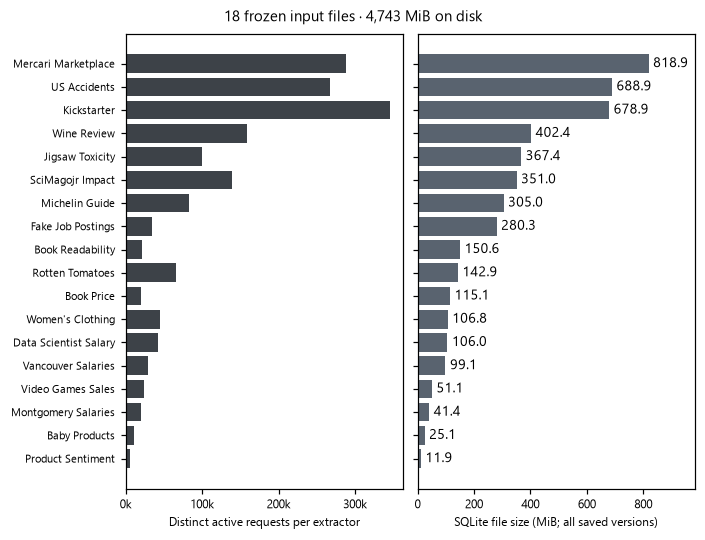

In [5]:
report_section("5. Actual saved input counts and exact reuse")
prepared_table = pd.DataFrame(prepared)
display_local(prepared_table[["dataset", "rows", "text_columns", "nonempty_slots", "empty_slots", "unique_inputs", "reused_slots", "avoided_percent", "reused"]])
fig, name, caption = prepared_storage_figure(prepared_table)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

## 6. Exact first-row inputs for all 18 datasets

The task sentence does not change between rows. It is filled with the documented target/class names; the row-specific text appears in `state.text`. The following objects reconstruct **all** first-row per-column/joint inputs from the saved files, including skipped empty slots. They contain no true target value. Provider-specific wrappers are shown in the exploration request-design notebook.

In [6]:
report_section("6. Exact first-row questions, options, task context and text")
for dataset in prepared:
    first_row = prepared_row(dataset["path"], 0, input_set_id=dataset["input_set_id"])
    display_json(dataset["dataset"] + " — original row csv:0", first_row)

## 7. Permanent inputs and downstream feature selection

There are exactly 18 SQLite input files directly in `data/decision_inputs/`; no question copy is exported to output. `question_banks` stores immutable question versions, `input_sets` records the source fingerprint and slot definitions, `unique_inputs` stores each distinct text group once, and `row_map` links every original row/slot to that input or a missing value. Changed wording/data produces a new version inside the same file.

Later, responses and numeric features go to a separate `data/jev_cache/<dataset_id>.sqlite3`, selected by provider + model/version + question/input version + representation. Logs and small run summaries go to `output_JEVPFN/1. question_preparation/`. Extraction logs will go to `output_JEVPFN/2. feature_creation/`. Only exact repeats for the same extractor configuration can reuse its response.

In [7]:
report_section("7. Saved files, versions and feature selection")
display_json("Prepared files", {"bank_id": bank["bank_id"], "folder": str(input_folder), "datasets": [{k: d[k] for k in ("dataset_id", "path", "input_set_id")} for d in prepared], "api_enabled": False})
display_json("Example later feature selection", {"provider": "jev", "model": "jev-1.13.0", "version": "1.13.0", "question_bank_id": bank["bank_id"], "question_variant": "documented", "representations": ["per_column", "joint"], "feature_view": "main"})
record("Jev and ten self-hosted adapters have offline tests; real GPU/provider compatibility and hosted billing remain pending. Full extraction is disabled.", "Implementation boundary")

## Complete preparation report

Every displayed definition, question, source, grouping count and first-row example is retained below and in `output_JEVPFN/All Results.md`.

In [8]:
finish_report(NOTEBOOK, f"Prepared {len(prepared)} dataset files with {sum(d['unique_inputs'] for d in prepared):,} unique inputs and {sum(d['reused_slots'] for d in prepared):,} repeated slots avoided. Bank: {bank['bank_id']}.\nQuestions and exact text groups are shared; each extractor gets separate responses. No inference or numeric feature creation.\n" + save.summary())

1. question_preparation/01_prepare_questions

1. Source-backed task schemas

              dataset                                                meaning                      task                         raw_target                                      target_meaning  classes  text_columns  review_notes
    Fake Job Postings              Employment Scam Aegean job advertisements     binary_classification                         fraudulent         whether the job advertisement is fraudulent        2             3             0
      Jigsaw Toxicity                         Jigsaw online comment toxicity     binary_classification                           Is Toxic                        whether the comment is toxic        2             1             0
          Kickstarter                            Kickstarter project funding     binary_classification                     Funding Status       whether the project achieved its funding goal        2             3             0
Data Scientist 